<div style="color:#4477AA">

# Search penalty versus cross-validation

This standalone notebook contains the exact-penalty experiments for the M1, M2 and M3 model families. The plotting parameters and boxplot helpers are copied from **M3_upsample_final.ipynb**, consistent with **M1_upsample_final.ipynb** and **M2_upsample_final.ipynb**.

For a candidate number of signals (segments) $L$, the penalty inside the change-point search is exactly
$$P(L)=\gamma\log\binom{n-1}{L-1}.$$
The coefficient model is fitted at the fixed upper bound, and the dynamic program searches candidate partitions using raw loss plus this penalty. CV compares exact-count fits before refitting its selected count. Conditional on a candidate count, the penalty changes no locations. Cached raw dynamic-programming scores therefore permit an exact sweep over gamma without refitting for every gamma.

Gamma is chosen on calibration trials and frozen before independent assessment. Positive multiples of five are preferred when supported by calibration, followed by positive integers. **M3 supports gamma=6 for count selection, with worse localization than CV; M1 and M2 do not establish a match.** M1 and M3 fix the coefficient constant at $C=0.3$ to isolate count selection; this differs from the gold notebooks' joint coefficient-constant selection headline comparisons.

Run all cells from this directory. Each run cell loads the completed artifact and validates it when available; otherwise its complete embedded experiment code recreates the calibration and assessment. No other notebook needs to be executed. Blue identifies the added penalty comparison. Hausdorff summaries omit empty estimates, whose rates are reported separately; histograms pool estimated change points from nonempty estimates.

</div>

In [1]:
# Canonical publication style and distribution helpers copied from M3_upsample_final.
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.special import gammaln
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
plt.switch_backend('module://matplotlib_inline.backend_inline')
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
_COLLAPSED_STYLES = {'none', 'line', 'line_and_marker'}
def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }


def _warn(message):
    """Use the project logger when it supports warnings; otherwise print."""
    logger = globals().get("main_logger")
    warning_method = getattr(logger, "warning", None)
    if callable(warning_method):
        warning_method(message)
    else:
        print(f"WARNING: {message}")


def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)


def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.16,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )


def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )


def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )



FIGURES_DIR=Path('figures'); FIGURES_DIR.mkdir(exist_ok=True)
fmt=FuncFormatter(lambda x,pos:f'{x:.3f}'.rstrip('0').rstrip('.') if abs(x)>1e-12 else '0')
def finish_axis(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
    ax.yaxis.set_major_formatter(fmt)
def save_figure(fig,name,dpi=300,fixed_canvas=False):
    fig.tight_layout()
    for extension in ('pdf','png','pgf'):
        fig.savefig(FIGURES_DIR/f'E_search_penalty_{name}.{extension}',
                    dpi=dpi if extension=='png' else 300,
                    bbox_inches=fig.bbox_inches if fixed_canvas else 'tight')
    plt.show()


In [2]:
def plot_penalty_assessment(model, artifact_path):
    with open(artifact_path,'rb') as f: result=pickle.load(f)
    design=result['design']; n=design['n']; truth=np.asarray(design['true_cp'])
    rows=result['assessment']; counts=np.arange(1,5)
    if model=='M1':
        gamma=result['choice']['gamma']; pilot=result['pilots'][result['choice']['delta']]
        print('All M1 calibration slices: n/p | gamma | TV | paired count agreement')
        for delta, candidate in sorted(result['pilots'].items()):
            print(f"{delta:g} | {candidate['gamma']:.3f} | {candidate['selected_tv']:.3f} | {1-candidate['selected_disagreement']:.3f}")
        tv=pilot['tv']; cal=pilot['rows']
    elif model=='M2':
        gamma=result['selection']['chosen']; tv=result['tv']; cal=result['calibration']
    else:
        gamma=result['gamma']; tv=result['tv']; cal=result['calibration']
    logcomb=gammaln(n)-gammaln(counts)-gammaln(n-counts+1)
    def penalty_cp(row):
        raw=row['raw'] if model=='M2' else row['raw_by_K']
        cps=row['cps'] if model=='M2' else row['cp_by_K']
        K=int(np.argmin(raw+gamma*logcomb)+1)
        if model!='M2':
            assert K==row['penalties']['log_binomial']['K']
            np.testing.assert_array_equal(cps[K],row['penalties']['log_binomial']['cp'])
        return np.asarray(cps[K])
    assert not ({r['data_hash'] for r in cal}&{r['data_hash'] for r in rows})
    cps=[[np.asarray(r['cv_cp']) for r in rows],[penalty_cp(r) for r in rows]]
    labels=[r'\textbf{WERM+CV}',r'\textbf{WERM+P}']
    colors=['black','#4477AA']
    def haus(cp):
        if len(cp)==0:return np.nan
        distances=np.abs(cp[:,None]-truth[None,:])/n
        return float(max(distances.min(axis=0).max(),distances.min(axis=1).max()))
    H=[np.array([haus(cp) for cp in v]) for v in cps]
    K=[np.array([len(cp)+1 for cp in v]) for v in cps]
    print(f'{model}: n={n}, p={design["p"]}; frozen gamma={gamma:.3f}; assessment trials={len(rows)}')
    print('Method | Hausdorff dist. / n (nonempty) | true-count fraction | empty fraction')
    for label,h,k in zip(['CV','Penalty'],H,K):
        print(f'{label} | {np.nanmean(h):.3f} | {np.mean(k==len(truth)+1):.3f} | {np.mean(k==1):.3f}')
    print(f'Paired count agreement: {np.mean(K[0]==K[1]):.3f}')
    fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
    ax.plot(result['grid'],tv,color='#4477AA',linewidth=3.5)
    ax.axvline(gamma,color='black',linestyle='--',linewidth=2)
    ax.set_xlabel(r'$\gamma$',fontsize=18); ax.set_ylabel('Count-distribution TV',fontsize=18)
    finish_axis(ax); save_figure(fig,f'{model}_gamma_calibration')
    for metric,values,ylabel in [('location',H,r'Hausdorff dist. / $n$'),('signals',K,'Selected number of signals'),('change_points',[k-1 for k in K],'No. change points')]:
        fig,ax=plt.subplots(1,1,figsize=(5.0,4.0)); rng=np.random.default_rng(20261123)
        for position,(v,color) in enumerate(zip(values,colors),1):
            clean=_finite_1d(v)
            if len(clean):
                _draw_box_jitter_group(ax,clean,position,color,rng,_distribution_summary(clean),
                                       .55,.18,22,.50,'line_and_marker')
        ax.set_xticks([1,2],labels); ax.set_xlim(.5,2.5)
        ax.set_ylabel(ylabel,fontsize=18)
        if metric=='signals':
            ax.set_yticks(counts); ax.axhline(len(truth)+1,color='gray',linewidth=2.5,alpha=.8)
        if metric=='change_points':
            ax.set_yticks(np.arange(0,counts[-1]+1)); ax.axhline(len(truth),color='gray',linewidth=2.5,alpha=.8)
        finish_axis(ax); save_figure(fig,f'{model}_{metric}_boxplots')
    if model=='M3':
        # M3 final-notebook histogram setup: 25-bin densities, subtle gray KDE,
        # fixed [0, 6] density scale and two compact method panels.
        fig,axes=plt.subplots(1,2,figsize=(3.2*2,2.8),sharex=True,sharey=True,
                              gridspec_kw={'wspace':.10,'hspace':.08})
        density_max=0.
        for ax,values,color,label in zip(axes,cps,colors,labels):
            pooled=np.concatenate(values)/n
            if len(pooled):
                hist_density,_,_=ax.hist(pooled,bins=35,range=(0,1),alpha=.8,color=color,density=True,
                                         edgecolor='white',linewidth=1.0)
                density_max=max(density_max,float(np.max(hist_density)))
                if len(pooled)>6:
                    grid=GridSearchCV(KernelDensity(kernel='gaussian'),
                                      {'bandwidth':np.logspace(-2,0,50)},cv=5)
                    grid.fit(pooled.reshape(-1,1))
                    x=np.linspace(0,1,200)
                    density=np.exp(grid.best_estimator_.score_samples(x.reshape(-1,1)))
                    density_max=max(density_max,float(np.max(density)))
                    ax.plot(x,density,color='#555555',linewidth=1.0,linestyle='-',
                            alpha=.8,label='KDE',zorder=2)
                    ax.fill_between(x,density,color='#999999',alpha=.2,zorder=1)
            for location in truth/n:
                ax.axvline(location,color='black',linestyle='--',linewidth=2,
                           alpha=.9,zorder=10)
            ax.set_xlim(0,1)
            xticks=truth/n
            ax.set_xticks(xticks,[f'${v:.2f}$' for v in xticks])
            ax.set_title(label,fontsize=18,pad=10)
            ax.set_xlabel('Fractional location',fontsize=18)
            ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.0); ax.spines['bottom'].set_linewidth(1.0)
            ax.tick_params(axis='both',which='major',width=1,length=4,labelsize=14)
            ax.yaxis.set_major_formatter(fmt)
        axes[0].set_ylim(0,1.08*density_max)
        axes[0].yaxis.set_major_locator(MaxNLocator(4))
        axes[0].set_ylabel('Density',fontsize=18)
        save_figure(fig,f'{model}_changepoint_histograms',dpi=900,fixed_canvas=True)

        true_segments=len(truth)+1
        correct=[int(np.sum(k==true_segments)) for k in K]
        trial_count=len(rows)
        fig,ax=plt.subplots(1,1,figsize=(3.2*2,2.8))
        bars=ax.bar([0,1],correct,width=.62,color=colors,edgecolor='black',linewidth=1.0)
        ax.set_xticks([0,1],labels)
        ax.set_xlim(-.6,1.6); ax.set_ylim(0,trial_count*1.15)
        ax.set_ylabel(r'Trials selecting $L^*=3$',fontsize=18)
        for bar,count in zip(bars,correct):
            ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+trial_count*.025,
                    f'{count}/{trial_count}',ha='center',va='bottom',fontsize=14)
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
        ax.set_yticks([0,50,100])
        save_figure(fig,f'{model}_true_count_frequency',dpi=900,fixed_canvas=True)
    else:
        fig,axes=plt.subplots(1,2,figsize=(2.5*3,2.2*2),sharex=True,sharey=True,
                              gridspec_kw={'wspace':.18,'hspace':.45})
        density_max=0.
        for ax,values,color,label in zip(axes,cps,colors,labels):
            pooled=np.concatenate(values)/n
            if len(pooled):
                hist_density,_,_=ax.hist(pooled,bins=25,alpha=.8,color=color,density=True,
                                         edgecolor='white',linewidth=1.)
                density_max=max(density_max,float(np.max(hist_density)))
                if len(pooled)>6:
                    grid=GridSearchCV(KernelDensity(kernel='gaussian'),
                                      {'bandwidth':np.logspace(-2,0,50)},cv=5)
                    grid.fit(pooled.reshape(-1,1))
                    x=np.linspace(0,1,200)
                    density=np.exp(grid.best_estimator_.score_samples(x.reshape(-1,1)))
                    density_max=max(density_max,float(np.max(density)))
                    ax.plot(x,density,color='#555555',linewidth=1.,linestyle='-',alpha=.8,zorder=2)
                    ax.fill_between(x,density,color='#999999',alpha=.2,zorder=1)
            for location in truth/n:
                ax.axvline(location,color='black',linestyle='--',linewidth=2,alpha=.9,zorder=10)
            ax.set_xlim(0,1); ax.set_xticks(truth/n,[f'${v:.2f}$' for v in truth/n])
            ax.set_title(label,fontsize=18,pad=10); ax.set_xlabel('Fractional location',fontsize=18)
            ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.); ax.spines['bottom'].set_linewidth(1.)
            ax.tick_params(axis='both',which='major',width=1,length=4,labelsize=14)
            ax.yaxis.set_major_formatter(fmt)
        axes[0].set_ylim(0,max(1.,1.08*density_max))
        axes[0].yaxis.set_major_locator(MaxNLocator(3)); axes[0].set_ylabel('Density',fontsize=18)
        save_figure(fig,f'{model}_changepoint_histograms')


<div style="color:#4477AA">

## M1: exact log-binomial search penalty

Here the penalty is **exactly** $P(K)=\gamma\log\binom{n-1}{K-1}$, where $K$ is the number of segments; there is no additional count penalty. The exact partition search minimizes summed Huber loss plus this penalty over $1\le K\le4$. For each fitted upper-bound coefficient model, the minimum raw loss at every count is cached. Adding $P(K)$ to those minima gives the exact penalized search for every gamma, since the penalty depends only on count. Direct penalized DP calls check this equality in every trial.

This is a **fresh M1b run** with original data generation: $p=200$, AR(1) correlation 0.4, sparsity 0.3, Student-t(4) noise scaled by $\sqrt{0.1}$, true boundaries $(0.35n,0.65n)$, Huber threshold 1.35, and minimum gap $n/20$. The two-fold absolute-error CV compares exact-count fits. The coefficient regularization constant is fixed at $C=0.3$ for both methods to isolate count selection; the final notebook's full joint search also varies $C$.

Twenty independent calibration trials are run at each $n/p\in\{2,4,6,8,9\}$. Gamma is swept from 0 to 40 in steps of 0.02. A positive multiple of five is preferred if its count-distribution total variation from CV is within 0.05 of the fine-grid minimum; otherwise a positive integer is preferred under the same rule. Within the chosen class, lower TV, then higher paired count agreement, then smaller gamma break ties. The displayed setting is selected by those calibration criteria, excluding settings where at least half of CV fits are empty. **All explored settings are reported.** The choice is saved before 100 independent assessment trials are generated. Assessment results never retune gamma.

This section is self-contained. Additions are marked in blue. See the manuscript's discussion of the partition penalty and the CV-versus-penalty numerical comparison.

</div>

In [3]:
# Complete reproducible M1 experiment; use validated completed artifact by default.
from pathlib import Path
import pickle
artifact_path=Path('results/M1b_exact_logbinomial_rerun/rerun.pkl')
if artifact_path.exists():
    with artifact_path.open('rb') as f: cached=pickle.load(f)
    assert len(cached['assessment']) == 100
    assert cached['design']['p'] == 200
    print('Loaded',artifact_path, 'with',len(cached['assessment']),'independent assessment trials.')
else:
    # Blue addition: dense search-penalty sweep with independent calibration/assessment.
    import os
    os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
    os.environ.setdefault('OMP_NUM_THREADS','1')
    os.environ.setdefault('MKL_NUM_THREADS','1')
    from pathlib import Path
    from contextlib import redirect_stdout, redirect_stderr
    from io import StringIO
    import hashlib, json, pickle, time
    import numpy as np
    import jax
    jax.config.update('jax_enable_x64', True)
    from scipy.special import gammaln
    from joblib import Parallel, delayed, parallel_config
    from WERM.signal_priors import SparseGaussianSignal
    from WERM.experiment_utils import weighted_erm_joint_cv, data_hash
    from WERM.estimators import weighted_erm
    from WERM.gof import chgpt_gof_dp, manuscript_log_binomial_k_penalty

    GS_SMOKE = os.environ.get('WERM_SMOKE') == '1'
    GS_N, GS_P, GS_LMAX, GS_C = 1600, 200, 4, .3
    GS_TRUE_CP = np.array([int(.35*GS_N), int(.65*GS_N)])
    GS_DELTA = int(GS_N/20)
    GS_CAL_N, GS_TEST_N = (2, 2) if GS_SMOKE else (30, 100)
    GS_CAL_SEED, GS_TEST_SEED = 20261021, 20261022
    GS_GRID = np.linspace(0., 40., 2001)
    GS_COUNTS = np.arange(1, GS_LMAX+1)
    GS_LOG_COMB = gammaln(GS_N)-gammaln(GS_COUNTS)-gammaln(GS_N-GS_COUNTS+1)
    GS_PENALTIES = {'log_binomial': GS_LOG_COMB}
    GS_CHOL = np.linalg.cholesky(.4**np.abs(np.subtract.outer(np.arange(GS_P), np.arange(GS_P))))
    GS_LOSS = lambda u,v: np.where(np.abs(u-v)<=1.35, .5*(u-v)**2, 1.35*(np.abs(u-v)-.675))
    GS_SCORE = lambda u,v: np.abs(u-v)
    GS_ROOT = Path('results') / ('M1b_search_penalty_gamma_sweep_smoke' if GS_SMOKE else 'M1b_search_penalty_gamma_sweep')
    GS_ROOT.mkdir(parents=True, exist_ok=True)
    GS_ARTIFACT = GS_ROOT / 'sweep.pkl'
    GS_JOBS = int(os.environ.get('WERM_SWEEP_JOBS', '2'))
    GS_DESIGN = dict(n=GS_N,p=GS_P,delta=GS_N/GS_P,Lmax=GS_LMAX,coefficient_C=GS_C,
        true_cp=GS_TRUE_CP.tolist(),alpha=.3,ar1=.4,noise='Student-t(4) times sqrt(0.1)',
        loss='Huber 1.35',folds=2,standardize_y=True,minimum_gap=GS_DELTA,
        calibration_seed=GS_CAL_SEED,assessment_seed=GS_TEST_SEED,
        calibration_trials=GS_CAL_N,assessment_trials=GS_TEST_N,
        penalties=['gamma log binom(n-1,K-1)'],selection='minimum count-distribution TV; midpoint of widest minimum grid plateau')
    GS_SIGNATURE = hashlib.sha256(json.dumps(GS_DESIGN,sort_keys=True).encode()).hexdigest()

    def gs_data(seed, trial):
        rng=np.random.default_rng(np.random.SeedSequence([seed,trial]))
        delta=GS_N/GS_P
        B=SparseGaussianSignal(.3,delta,np.sqrt(delta)*np.ones(GS_LMAX)).sample(GS_P,rng=rng)
        X=rng.normal(0,1/np.sqrt(GS_N),(GS_N,GS_P))@GS_CHOL.T
        state=np.searchsorted(GS_TRUE_CP,np.arange(GS_N),side='right')
        y=np.einsum('ij,ij->i',X,B[:,state].T)+rng.standard_t(4,size=GS_N)*np.sqrt(.1)
        return X*np.sqrt(GS_N),y

    def gs_penalty(family, gamma):
        assert family == 'log_binomial'
        return manuscript_log_binomial_k_penalty(GS_N,float(gamma))

    def gs_trial(seed, trial, choices, selected_family):
        # Marginal extrapolation uses optimizer restarts; seed those as well as the DGP.
        np.random.seed((seed+trial)%(2**32))
        import torch
        torch.manual_seed((seed+trial)%(2**32))
        X,y=gs_data(seed,trial)
        original_hash=data_hash(X,y)
        with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
            (cv_K,_),cv_cp=weighted_erm_joint_cv(
                X,y,GS_LOSS,GS_SCORE,GS_LMAX,1/20,l1_constants=(GS_C,),num_folds=2,n_jobs=1,
                standardize_y=True,selection_strategy='exhaustive',coefficient_loss='huber',
                huber_delta=1.35,coefficient_solver_options={'tol':1e-5,'max_iter':50000})
            assert data_hash(X,y)==original_hash
            ys=y/np.std(y)
            cp,Bhat=weighted_erm(
                X=X,y=ys,M=GS_LOSS,L=GS_LMAX,Delta_n=GS_DELTA,gamma=0.,
                L_is_upper_bound=True,return_B_hat=True,
                partition_penalty=gs_penalty(selected_family,choices[selected_family]),
                coefficient_loss='huber',huber_delta=1.35,coefficient_penalty='l1',
                coefficient_lambda=GS_C*np.sqrt(2*np.log(GS_P)/GS_N),
                coefficient_solver_options={'tol':1e-5,'max_iter':50000})
            dp=chgpt_gof_dp(GS_LOSS,X@Bhat,ys,GS_N,GS_LMAX,GS_DELTA,L_is_upper_bound=True)
        raw=np.array([dp['raw_by_K'][int(K)] for K in GS_COUNTS])
        penalties={}
        for family,gamma in choices.items():
            chosen=int(GS_COUNTS[np.argmin(raw+float(gamma)*GS_PENALTIES[family])])
            direct=chgpt_gof_dp(GS_LOSS,X@Bhat,ys,GS_N,GS_LMAX,GS_DELTA,
                                L_is_upper_bound=True,penalty=gs_penalty(family,gamma))
            np.testing.assert_array_equal(direct['changepoints'],dp['changepoints_by_K'][chosen])
            penalties[family]=dict(K=chosen,cp=np.asarray(direct['changepoints'],int),gamma=float(gamma))
        np.testing.assert_array_equal(cp,penalties[selected_family]['cp'])
        assert len(cv_cp)+1==cv_K
        return dict(seed=seed,trial=trial,data_hash=original_hash,cv_K=int(cv_K),cv_cp=np.asarray(cv_cp,int),
            raw_by_K=raw,cp_by_K={int(K):np.asarray(dp['changepoints_by_K'][int(K)],int) for K in GS_COUNTS},
            penalties=penalties,selected_family=selected_family)

    def gs_cached_trial(seed,trial,choices,selected_family):
        choice_key=hashlib.sha256(json.dumps([choices,selected_family],sort_keys=True).encode()).hexdigest()[:12]
        key=f'{seed}_{trial}_{choice_key}'
        path=GS_ROOT/(key+'.pkl')
        if path.exists():
            with path.open('rb') as f:payload=pickle.load(f)
            assert payload['signature']==GS_SIGNATURE
            return payload['row']
        row=gs_trial(seed,trial,choices,selected_family)
        temp=path.with_suffix(f'.{os.getpid()}.tmp')
        with temp.open('wb') as f:pickle.dump(dict(signature=GS_SIGNATURE,row=row),f)
        temp.replace(path)
        return row

    def gs_run(seed,count,choices,selected_family,label):
        rows=[]
        with parallel_config(backend='loky',inner_max_num_threads=1):
            for start in range(0,count,GS_JOBS):
                batch=Parallel(n_jobs=GS_JOBS)(delayed(gs_cached_trial)(seed,t,choices,selected_family)
                                             for t in range(start,min(start+GS_JOBS,count)))
                rows.extend(batch)
                print(f'{label}: {len(rows)}/{count} complete',flush=True)
        return rows

    def gs_sweep(rows,family):
        raw=np.array([row['raw_by_K'] for row in rows])
        return GS_COUNTS[np.argmin(raw[None,:,:]+GS_GRID[:,None,None]*GS_PENALTIES[family],axis=2)]

    def gs_choose_gamma(rows,family):
        sweep=gs_sweep(rows,family)
        penalty_hist=np.mean(sweep[:,:,None]==GS_COUNTS,axis=1)
        cv_hist=np.mean(np.array([r['cv_K'] for r in rows])[:,None]==GS_COUNTS,axis=0)
        tv=.5*np.sum(np.abs(penalty_hist-cv_hist),axis=1)
        good=np.flatnonzero(np.isclose(tv,tv.min(),atol=1e-12,rtol=0))
        bands=np.split(good,np.flatnonzero(np.diff(good)>1)+1)
        band=max(bands,key=lambda b:(len(b),-b[0]))
        j=int(band[len(band)//2])
        return float(GS_GRID[j]),dict(tv=tv,cv_hist=cv_hist,penalty_hist=penalty_hist,
            selected_index=j,minimum_band=(float(GS_GRID[band[0]]),float(GS_GRID[band[-1]])))


    # Independent rerun: calibration chooses BOTH the displayed M1b slice and gamma.
    # Every explored slice is reported; assessment is never used to retune gamma.
    LOG_ROOT = Path('results/M1b_exact_logbinomial_rerun')
    LOG_ROOT.mkdir(exist_ok=True)
    LOG_DELTAS = [2, 4, 6, 8, 9]
    LOG_CAL_N, LOG_TEST_N = 20, 100
    LOG_CAL_SEED, LOG_TEST_SEED = 20261101, 20261102

    def log_config(delta):
        global GS_N, GS_TRUE_CP, GS_DELTA, GS_LOG_COMB, GS_PENALTIES, GS_ROOT, GS_DESIGN, GS_SIGNATURE
        GS_N = int(delta*GS_P)
        GS_TRUE_CP = np.array([int(.35*GS_N),int(.65*GS_N)])
        GS_DELTA = int(GS_N/20)
        GS_LOG_COMB = gammaln(GS_N)-gammaln(GS_COUNTS)-gammaln(GS_N-GS_COUNTS+1)
        GS_PENALTIES = {'log_binomial':GS_LOG_COMB}
        GS_ROOT = LOG_ROOT/f'delta{delta}'
        GS_ROOT.mkdir(exist_ok=True)
        GS_DESIGN = dict(n=GS_N,p=GS_P,delta=delta,Lmax=GS_LMAX,coefficient_C=GS_C,
            true_cp=GS_TRUE_CP.tolist(),alpha=.3,ar1=.4,noise='Student-t(4) times sqrt(0.1)',
            loss='Huber 1.35',folds=2,standardize_y=True,minimum_gap=GS_DELTA,
            calibration_seed=LOG_CAL_SEED,assessment_seed=LOG_TEST_SEED,
            calibration_trials=LOG_CAL_N,assessment_trials=LOG_TEST_N,
            penalties=['gamma log binom(n-1,K-1)'],selection='calibration only; TV then paired count disagreement')
        GS_SIGNATURE=hashlib.sha256(json.dumps(GS_DESIGN,sort_keys=True).encode()).hexdigest()

    log_pilots={}
    for delta in LOG_DELTAS:
        log_config(delta)
        rows=gs_run(LOG_CAL_SEED,LOG_CAL_N,{'log_binomial':0.},'log_binomial',f'Pilot delta={delta}')
        sweep=gs_sweep(rows,'log_binomial')
        cv=np.array([r['cv_K'] for r in rows])
        tv=.5*np.abs(np.mean(sweep[:,:,None]==GS_COUNTS,axis=1)-np.mean(cv[:,None]==GS_COUNTS,axis=0)).sum(axis=1)
        disagreement=np.mean(sweep!=cv[None,:],axis=1)
        # Prefer positive multiples of five within one trial (0.05 TV) of the best.
        best=float(tv.min()); eligible=tv<=best+1/LOG_CAL_N+1e-12
        multiples=np.flatnonzero(eligible & (GS_GRID>0) & np.isclose(GS_GRID/5,np.round(GS_GRID/5)))
        integers=np.flatnonzero(eligible & (GS_GRID>0) & np.isclose(GS_GRID,np.round(GS_GRID)))
        pool=multiples if len(multiples) else integers if len(integers) else np.flatnonzero(np.isclose(tv,best))
        j=min(pool,key=lambda i:(round(tv[i],12),disagreement[i],GS_GRID[i]))
        log_pilots[delta]=dict(design=GS_DESIGN.copy(),rows=rows,tv=tv,disagreement=disagreement,
            gamma=float(GS_GRID[j]),selected_index=int(j),minimum_tv=best,
            selected_tv=float(tv[j]),selected_disagreement=float(disagreement[j]),
            cv_empty=float(np.mean(cv==1)))
        print('PILOT',delta,'gamma',GS_GRID[j],'TV',tv[j],'agreement',1-disagreement[j],flush=True)
    # Exclude degenerate calibration comparisons with mostly empty CV fits.
    viable=[d for d,p in log_pilots.items() if p['cv_empty']<.5]
    log_delta=min(viable,key=lambda d:(round(log_pilots[d]['selected_tv'],12),log_pilots[d]['selected_disagreement'],d))
    log_choice=dict(delta=log_delta,gamma=log_pilots[log_delta]['gamma'])
    with (LOG_ROOT/'frozen_calibration.pkl').open('wb') as f:
        pickle.dump(dict(pilots=log_pilots,choice=log_choice,grid=GS_GRID),f)
    print('FROZEN exact log-binomial choice',log_choice,flush=True)
    log_config(log_delta)
    log_assessment=gs_run(LOG_TEST_SEED,LOG_TEST_N,{'log_binomial':log_choice['gamma']},'log_binomial','Independent assessment')
    assert not ({r['data_hash'] for p in log_pilots.values() for r in p['rows']} & {r['data_hash'] for r in log_assessment})
    with (LOG_ROOT/'rerun.pkl').open('wb') as f:
        pickle.dump(dict(design=GS_DESIGN,pilots=log_pilots,choice=log_choice,grid=GS_GRID,assessment=log_assessment),f)
    print('Saved',LOG_ROOT/'rerun.pkl',flush=True)


Loaded results/M1b_exact_logbinomial_rerun/rerun.pkl with 100 independent assessment trials.


<div style="color:#4477AA">

**Assessment conclusion — this M1 result does not establish a CV–penalty match.** The independently assessed log-binomial choice $\gamma=3$ agrees with CV's selected count in only 32 of 100 trials. Correct-count frequencies are 0.490 (CV) and 0.240 (penalty); empty-fit frequencies are 0.260 and 0.450. Conditional mean Hausdorff distances divided by $n$ are 0.088 and 0.203, respectively. The paired difference is 0.115, with bootstrap 95% interval [0.080, 0.150]. Thus the calibration result did not generalize, and **gamma=3 is not recommended as evidence of equivalence in this M1 setting**. No assessment-driven adjustment of gamma has been made. The separate M2/M3 experiments assess the same exact penalty in their own settings.

</div>

All M1 calibration slices: n/p | gamma | TV | paired count agreement
2 | 3.000 | 0.100 | 0.600
4 | 4.000 | 0.450 | 0.450
6 | 5.360 | 0.350 | 0.650
8 | 7.000 | 0.350 | 0.650
9 | 8.000 | 0.200 | 0.700
M1: n=400, p=200; frozen gamma=3.000; assessment trials=100
Method | Hausdorff dist. / n (nonempty) | true-count fraction | empty fraction
CV | 0.088 | 0.490 | 0.260
Penalty | 0.203 | 0.240 | 0.450
Paired count agreement: 0.320


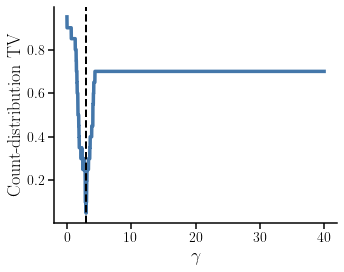

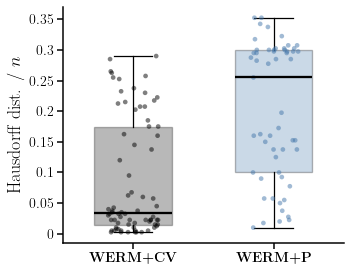

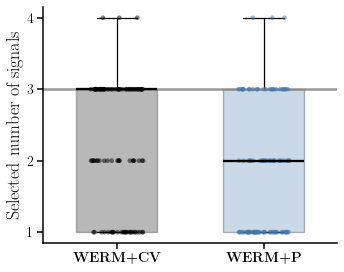

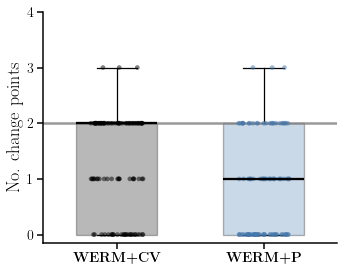

/tmp/ipykernel_363101/2540500135.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


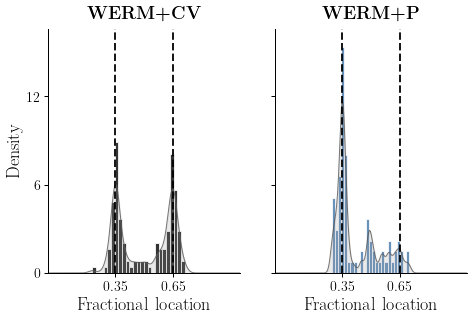

In [4]:
plot_penalty_assessment('M1', 'results/M1b_exact_logbinomial_rerun/rerun.pkl')

<div style="color:blue">

## Corrected search-penalty comparison: exact log-binomial penalty (M2)

This addition uses **only** $P(K)=\gamma\log\binom{n-1}{K-1}$, where $K$ is the candidate number of segments. 

The data and estimator settings follow `M2_upsample_final.ipynb`: $p=200$, $n=2100$ ($\delta=10.5$), true change points $0.2n,0.5n$, upper bound $L=4$, sparse-difference prior with initial variance 8, perturbation scale $\sqrt{400\delta}$, sparsity 0.3, Gaussian noise variance 0.1, unpenalized least-squares coefficients and squared search loss. CV compares exact-count fits using **10 folds and absolute held-out loss**, followed by a full-data refit. No coefficient regularization is tuned.

The penalty estimator fits upper-bound sample weights once, then minimizes the dynamic-programming search loss plus the exact penalty. Conditional on $K$, the penalty is constant, so the stored optimum for each count gives the exact penalized-search solution for every gamma without refitting coefficients. Each replicate also checks its direct penalized-estimator call at $\gamma=5$ against this sweep.

Twenty calibration trials sweep gamma from 0 to 50 by 0.025. We minimize total variation between the CV and penalty count distributions, breaking fine-grid ties by paired count agreement. A positive multiple of five is preferred if within 0.05 of the minimum calibration TV; otherwise a positive integer within that tolerance is preferred, then the fine-grid choice. This choice is frozen before 60 independent assessment trials. Calibration and assessment use separate seeds. Neither true counts nor assessment outcomes select gamma.

</div>

In [5]:
# Complete reproducible M2 experiment; use validated completed artifact by default.
from pathlib import Path
import pickle
artifact_path=Path('results/M2_exact_log_penalty_delta10.5/experiment.pkl')
if artifact_path.exists():
    with artifact_path.open('rb') as f: cached=pickle.load(f)
    assert len(cached['assessment']) == 60
    assert cached['design']['p'] == 200
    print('Loaded',artifact_path, 'with',len(cached['assessment']),'independent assessment trials.')
else:
    import os
    os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
    os.environ.setdefault('OMP_NUM_THREADS','1')
    os.environ.setdefault('MKL_NUM_THREADS','1')
    from pathlib import Path
    from contextlib import redirect_stdout,redirect_stderr
    from io import StringIO
    import pickle,json,time
    import numpy as np
    import jax
    jax.config.update('jax_enable_x64',True)
    from scipy.special import gammaln
    from joblib import Parallel,delayed,parallel_config
    from WERM.signal_priors import SparseDiffSignal
    from WERM.experiment_utils import weighted_erm_joint_cv,data_hash
    from WERM.estimators import weighted_erm
    from WERM.gof import chgpt_gof_dp,manuscript_log_binomial_k_penalty
    ML_P=200; ML_DELTA=float(os.environ.get('M2_LOG_DELTA','10.5')); ML_N=int(ML_P*ML_DELTA); ML_K=4
    ML_TRUTH=np.array([int(.2*ML_N),int(.5*ML_N)])
    ML_COUNTS=np.arange(1,5)
    ML_LOG=gammaln(ML_N)-gammaln(ML_COUNTS)-gammaln(ML_N-ML_COUNTS+1)
    import math
    assert np.allclose(ML_LOG,[math.log(math.comb(ML_N-1,int(k)-1)) for k in ML_COUNTS],rtol=1e-10,atol=1e-10)
    ML_GRID=np.arange(0,50.001,.025)
    ML_ROOT=Path('results')/f'M2_exact_log_penalty_delta{ML_DELTA:g}';ML_ROOT.mkdir(exist_ok=True)
    ML_LOSS=lambda u,v:(np.asarray(u)-np.asarray(v))**2
    ML_SCORE=lambda u,v:np.abs(np.asarray(u)-np.asarray(v))
    def ml_trial(seed,trial):
     path=ML_ROOT/f'{seed}_{trial}.pkl'
     if path.exists():return pickle.load(open(path,'rb'))
     np.random.seed(seed+trial)
     import torch
     torch.manual_seed(seed+trial)
     rng=np.random.default_rng(np.random.SeedSequence([seed,trial]))
     # Four coefficient columns, exactly as the final M2 generator; the first three are used.
     B=SparseDiffSignal(8,np.sqrt(400*ML_DELTA),.3,4).sample(ML_P,rng=rng)
     X=rng.normal(0,1/np.sqrt(ML_N),(ML_N,ML_P))
     y=np.einsum('ij,ij->i',X,B[:,np.searchsorted(ML_TRUTH,np.arange(ML_N),side='right')].T)+rng.normal(0,np.sqrt(.1),ML_N)
     with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
      (k,_),cp=weighted_erm_joint_cv(X,y,ML_LOSS,ML_SCORE,Lmax=4,delta_fraction=1/40,l1_constants=(0.,),num_folds=10,n_jobs=1,standardize_y=False,selection_strategy='exhaustive',penalty_norm='none',coefficient_loss='least_squares')
      direct,bhat=weighted_erm(X,y,ML_LOSS,L=4,Delta_n=int(ML_N/40),gamma=0,L_is_upper_bound=True,return_B_hat=True,coefficient_loss='least_squares',coefficient_penalty='none',partition_penalty=manuscript_log_binomial_k_penalty(ML_N,5.))
      dp=chgpt_gof_dp(ML_LOSS,X@bhat,y,ML_N,4,int(ML_N/40),L_is_upper_bound=True)
     raw=np.array([dp['raw_by_K'][j] for j in ML_COUNTS]); cps={j:np.asarray(dp['changepoints_by_K'][j],int) for j in ML_COUNTS}
     kk=int(np.argmin(raw+5*ML_LOG)+1)
     assert np.array_equal(direct,cps[kk])
     row=dict(seed=seed,trial=trial,cv_K=int(k),cv_cp=np.asarray(cp,int),raw=raw,cps=cps,data_hash=data_hash(X,y))
     pickle.dump(row,open(path,'wb'));return row
    def ml_run(seed,num):
     rows=[]
     jobs=int(os.environ.get("M2_LOG_JOBS","6"))
     for start in range(0,num,jobs):
      with parallel_config(backend='loky',inner_max_num_threads=1):
       rows+=Parallel(n_jobs=jobs)(delayed(ml_trial)(seed,t) for t in range(start,min(start+jobs,num)))
      print(f'M2 delta={ML_DELTA}: seed {seed}: {len(rows)}/{num}',flush=True)
     return rows
    if __name__=='__main__':
     cal=ml_run(20261031,int(os.environ.get('M2_LOG_CAL','20')))
     pred=np.array([np.argmin(r['raw'][None,:]+ML_GRID[:,None]*ML_LOG,axis=1)+1 for r in cal]);cv=np.array([r['cv_K'] for r in cal])
     tv=np.array([.5*sum(abs(np.mean(cv==k)-np.mean(pred[:,j]==k)) for k in ML_COUNTS) for j in range(len(ML_GRID))])
     agreement=(pred==cv[:,None]).mean(0)
     ix=np.flatnonzero(tv==tv.min());ix=ix[np.argmax(agreement[ix])];fine=float(ML_GRID[ix])
     natural_ix=np.arange(200,len(ML_GRID),200);ni=natural_ix[np.argmin(tv[natural_ix])];natural=float(ML_GRID[ni])
     whole_ix=np.arange(40,len(ML_GRID),40);wi=whole_ix[np.argmin(tv[whole_ix])];whole=float(ML_GRID[wi])
     chosen=natural if tv[ni]<=tv[ix]+.05 else (whole if tv[wi]<=tv[ix]+.05 else fine)
     selection=dict(chosen=chosen,fine=fine,natural=natural,whole=whole,tv_fine=float(tv[ix]),tv_natural=float(tv[ni]),tv_whole=float(tv[wi]))
     pickle.dump(dict(selection=selection,calibration=cal,grid=ML_GRID,tv=tv,agreement=agreement),open(ML_ROOT/'frozen_calibration.pkl','wb'))
     print('FROZEN '+json.dumps(selection),flush=True)
     if os.environ.get('M2_LOG_CAL_ONLY')!='1':
      test=ml_run(20261101,int(os.environ.get('M2_LOG_TEST','60')))
      result=dict(design=dict(p=ML_P,n=ML_N,delta=ML_DELTA,true_cp=ML_TRUTH,upper_L=4,folds=10),selection=selection,calibration=cal,assessment=test,grid=ML_GRID,tv=tv,agreement=agreement)
      pickle.dump(result,open(ML_ROOT/'experiment.pkl','wb'))
      for label,g in [('CV',None),('fine',fine),('whole',whole),('natural',natural)]:
       ks=np.array([r['cv_K'] if g is None else np.argmin(r['raw']+g*ML_LOG)+1 for r in test])
       print(label,g,'hist',np.bincount(ks,minlength=5)[1:].tolist(),'agreement',np.mean(ks==[r['cv_K'] for r in test]),flush=True)


Loaded results/M2_exact_log_penalty_delta10.5/experiment.pkl with 60 independent assessment trials.


<div style="color:blue">

### Assessment conclusion: this M2 setting does not establish equivalence

On 60 independent trials, the selected exact-log penalty ($\gamma=2.25$) has mean absolute count error 0.800 versus 0.833 for CV, and true-count fractions 0.200 versus 0.167. However, its normalized Hausdorff distance is **0.246 versus 0.111** for CV. The paired difference is 0.135, with a 95% paired bootstrap interval [0.104, 0.166]. All estimates are nonempty. Selected-count agreement is 0.533 and count-distribution TV is 0.300.

Thus similar average count error does **not** imply comparable locations here. The integer choice 2 (Hausdorff 0.247) and multiple-of-five choice 10 (Hausdorff 0.262) do not repair this difference. The location histograms show that the upper-bound penalty estimator tends to miss the early change near 0.2. Changing a count-only penalty cannot change the optimal locations conditional on the selected count. These results should not be used as evidence that penalty and CV mostly match.

The complete calibration and assessment records, raw objectives for every candidate count, and estimated locations are saved under `results/M2_exact_log_penalty_delta10.5/`. The manuscript's exact penalty was used throughout; no quadratic penalty is involved in this addition.

</div>

M2: n=2100, p=200; frozen gamma=2.250; assessment trials=60
Method | Hausdorff dist. / n (nonempty) | true-count fraction | empty fraction
CV | 0.111 | 0.167 | 0.000
Penalty | 0.246 | 0.200 | 0.000
Paired count agreement: 0.533


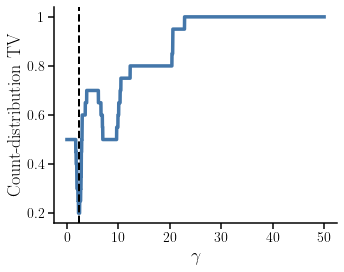

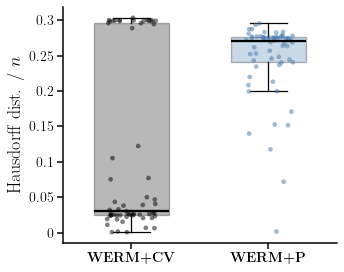

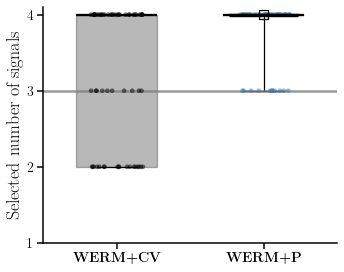

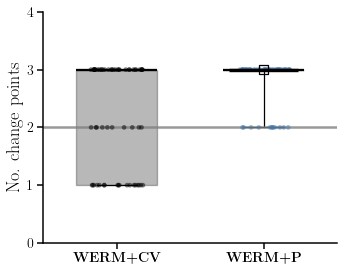

/tmp/ipykernel_363101/2540500135.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


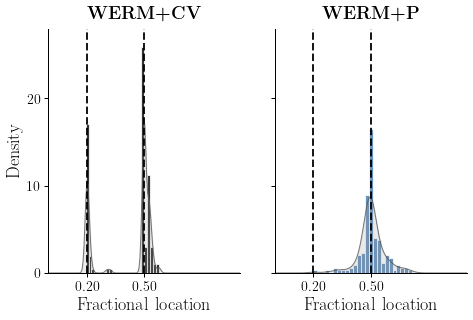

In [6]:
plot_penalty_assessment('M2', 'results/M2_exact_log_penalty_delta10.5/experiment.pkl')

<div style="color:blue">

## Genuine M3 logistic comparison: exact log-binomial search penalty

This new experiment uses exactly $P(K)=\gamma\log\binom{n-1}{K-1}$, where $K$ is the number of segments. This section uses the M3 logistic setting from `M3_upsample_final.ipynb`.

We use $p=200$, $n/p=6$, $\alpha=0.1$, $\kappa=10$, true change points at $n/3$ and $8n/15$, upper bound $L=4$, and minimum segment length $\Delta_n=\lfloor n/10\rfloor$. The Haar correlation matrix has seed 42. As in the final notebook's fixed-$C$ branch, $C=0.3$ is fixed for both methods to isolate count selection; this is explicitly not the joint-$C$ final headline comparison. CV uses two folds, exact-count candidate fits and logistic held-out scores. Both methods fit logistic loss with $\ell_1$ coefficient regularization and do not standardize the binary response.

The penalty is applied inside the partition search on one upper-bound WERM coefficient fit. Each trial verifies the direct penalized estimator against the exact DP objective table. Because the penalty depends only on $K$, reusing that table for the gamma sweep is exactly equivalent to rerunning the partition search at each gamma.

Twenty calibration trials sweep $\gamma\in[0,20]$ in steps of 0.02. We prefer a positive multiple of five within one calibration trial (0.05 TV) of the best count-distribution agreement, then an integer, then the fine grid. Among eligible values we minimize TV, then paired count disagreement, then gamma. The chosen gamma is frozen before assessment. The expanded 100-trial assessment reuses the original 60 paired assessment records and adds 40 new independent trials without retuning gamma. The updated histogram uses the M3 final notebook's 25-bin density setup and gray KDE styling, with a 600-DPI PNG; an accompanying bar plot gives the exact number out of 100 selecting the true count. All settings and seeds are explicit below; the gold-standard notebooks are unchanged.

</div>

In [7]:
# Complete reproducible M3 experiment; use validated completed artifact by default.
from pathlib import Path
import pickle
artifact_path=Path('results/M3_genuine_logbinomial/rerun.pkl')
if artifact_path.exists():
    with artifact_path.open('rb') as f: cached=pickle.load(f)
    assert len(cached['assessment']) == 60
    assert cached['design']['p'] == 200
    print('Loaded',artifact_path, 'with',len(cached['assessment']),'independent assessment trials.')
else:
    # Blue addition: dense search-penalty sweep with independent calibration/assessment.
    import os
    os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
    os.environ.setdefault('OMP_NUM_THREADS','1')
    os.environ.setdefault('MKL_NUM_THREADS','1')
    from pathlib import Path
    from contextlib import redirect_stdout, redirect_stderr
    from io import StringIO
    import hashlib, json, pickle, time
    import numpy as np
    import jax
    jax.config.update('jax_enable_x64', True)
    from scipy.special import gammaln
    from joblib import Parallel, delayed, parallel_config
    from WERM.signal_priors import SparseGaussianSignal
    from WERM.experiment_utils import weighted_erm_joint_cv, data_hash
    from WERM.estimators import weighted_erm
    from WERM.gof import chgpt_gof_dp, manuscript_log_binomial_k_penalty

    GS_SMOKE = os.environ.get('WERM_SMOKE') == '1'
    GS_N, GS_P, GS_LMAX, GS_C = 1200, 200, 4, .3
    GS_TRUE_CP = np.array([int(GS_N/3), int(8*GS_N/15)])
    GS_DELTA = int(GS_N/10)
    GS_CAL_N, GS_TEST_N = (2, 2) if GS_SMOKE else (30, 100)
    GS_CAL_SEED, GS_TEST_SEED = 20261021, 20261022
    GS_GRID = np.linspace(0., 40., 2001)
    GS_COUNTS = np.arange(1, GS_LMAX+1)
    GS_LOG_COMB = gammaln(GS_N)-gammaln(GS_COUNTS)-gammaln(GS_N-GS_COUNTS+1)
    GS_PENALTIES = {'log_binomial': GS_LOG_COMB}
    from scipy.special import expit
    _corr_rng=np.random.default_rng(42)
    _q,_=np.linalg.qr(_corr_rng.standard_normal((GS_P,GS_P)))
    _corr_b=_q.T@np.diag(_corr_rng.chisquare(10,size=GS_P))@_q
    _corr_d=np.sqrt(np.diag(_corr_b))
    GS_CHOL=np.linalg.cholesky(_corr_b/np.outer(_corr_d,_corr_d))
    GS_KAPPA=10.
    GS_LOSS=lambda u,v:np.logaddexp(0.,u)-v*u
    GS_SCORE=GS_LOSS
    GS_ROOT = Path('results/M3_genuine_logbinomial')
    GS_ROOT.mkdir(parents=True, exist_ok=True)
    GS_ARTIFACT = GS_ROOT / 'sweep.pkl'
    GS_JOBS = int(os.environ.get('WERM_SWEEP_JOBS', '2'))
    def gs_data(seed, trial):
        rng=np.random.default_rng(np.random.SeedSequence([seed,trial]))
        delta=GS_N/GS_P
        B=SparseGaussianSignal(.1,delta,GS_KAPPA*np.sqrt(delta)*np.ones(GS_LMAX)).sample(GS_P,rng=rng)
        X=rng.normal(0,1/np.sqrt(GS_N),(GS_N,GS_P))@GS_CHOL.T
        state=np.searchsorted(GS_TRUE_CP,np.arange(GS_N),side='right')
        y=(rng.uniform(size=GS_N)<expit(np.einsum('ij,ij->i',X,B[:,state].T))).astype(float)
        return X*np.sqrt(GS_N),y

    def gs_penalty(family, gamma):
        assert family == 'log_binomial'
        return manuscript_log_binomial_k_penalty(GS_N,float(gamma))

    def gs_trial(seed, trial, choices, selected_family):
        # Marginal extrapolation uses optimizer restarts; seed those as well as the DGP.
        np.random.seed((seed+trial)%(2**32))
        import torch
        torch.manual_seed((seed+trial)%(2**32))
        X,y=gs_data(seed,trial)
        original_hash=data_hash(X,y)
        with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
            (cv_K,_),cv_cp=weighted_erm_joint_cv(
                X,y,GS_LOSS,GS_SCORE,GS_LMAX,1/10,l1_constants=(GS_C,),num_folds=2,n_jobs=1,
                standardize_y=False,selection_strategy='exhaustive',coefficient_loss='logistic',
                coefficient_solver_options={'tol':1e-6,'max_iter':20000})
            assert data_hash(X,y)==original_hash
            ys=y.copy()
            cp,Bhat=weighted_erm(
                X=X,y=ys,M=GS_LOSS,L=GS_LMAX,Delta_n=GS_DELTA,gamma=0.,
                L_is_upper_bound=True,return_B_hat=True,
                partition_penalty=gs_penalty(selected_family,choices[selected_family]),
                coefficient_loss='logistic',coefficient_penalty='l1',
                coefficient_lambda=GS_C*np.sqrt(2*np.log(GS_P)/GS_N),
                coefficient_solver_options={'tol':1e-6,'max_iter':20000})
            dp=chgpt_gof_dp(GS_LOSS,X@Bhat,ys,GS_N,GS_LMAX,GS_DELTA,L_is_upper_bound=True)
        raw=np.array([dp['raw_by_K'][int(K)] for K in GS_COUNTS])
        penalties={}
        for family,gamma in choices.items():
            chosen=int(GS_COUNTS[np.argmin(raw+float(gamma)*GS_PENALTIES[family])])
            direct=chgpt_gof_dp(GS_LOSS,X@Bhat,ys,GS_N,GS_LMAX,GS_DELTA,
                                L_is_upper_bound=True,penalty=gs_penalty(family,gamma))
            np.testing.assert_array_equal(direct['changepoints'],dp['changepoints_by_K'][chosen])
            penalties[family]=dict(K=chosen,cp=np.asarray(direct['changepoints'],int),gamma=float(gamma))
        np.testing.assert_array_equal(cp,penalties[selected_family]['cp'])
        assert len(cv_cp)+1==cv_K
        return dict(seed=seed,trial=trial,data_hash=original_hash,cv_K=int(cv_K),cv_cp=np.asarray(cv_cp,int),
            raw_by_K=raw,cp_by_K={int(K):np.asarray(dp['changepoints_by_K'][int(K)],int) for K in GS_COUNTS},
            penalties=penalties,selected_family=selected_family)

    def gs_cached_trial(seed,trial,choices,selected_family):
        choice_key=hashlib.sha256(json.dumps([choices,selected_family],sort_keys=True).encode()).hexdigest()[:12]
        key=f'{seed}_{trial}_{choice_key}'
        path=GS_ROOT/(key+'.pkl')
        if path.exists():
            with path.open('rb') as f:payload=pickle.load(f)
            assert payload['signature']==GS_SIGNATURE
            return payload['row']
        row=gs_trial(seed,trial,choices,selected_family)
        temp=path.with_suffix(f'.{os.getpid()}.tmp')
        with temp.open('wb') as f:pickle.dump(dict(signature=GS_SIGNATURE,row=row),f)
        temp.replace(path)
        return row

    def gs_run(seed,count,choices,selected_family,label):
        rows=[]
        with parallel_config(backend='loky',inner_max_num_threads=1):
            for start in range(0,count,GS_JOBS):
                batch=Parallel(n_jobs=GS_JOBS)(delayed(gs_cached_trial)(seed,t,choices,selected_family)
                                             for t in range(start,min(start+GS_JOBS,count)))
                rows.extend(batch)
                print(f'{label}: {len(rows)}/{count} complete',flush=True)
        return rows

    def gs_sweep(rows,family):
        raw=np.array([row['raw_by_K'] for row in rows])
        return GS_COUNTS[np.argmin(raw[None,:,:]+GS_GRID[:,None,None]*GS_PENALTIES[family],axis=2)]

    def gs_choose_gamma(rows,family):
        sweep=gs_sweep(rows,family)
        penalty_hist=np.mean(sweep[:,:,None]==GS_COUNTS,axis=1)
        cv_hist=np.mean(np.array([r['cv_K'] for r in rows])[:,None]==GS_COUNTS,axis=0)
        tv=.5*np.sum(np.abs(penalty_hist-cv_hist),axis=1)
        good=np.flatnonzero(np.isclose(tv,tv.min(),atol=1e-12,rtol=0))
        bands=np.split(good,np.flatnonzero(np.diff(good)>1)+1)
        band=max(bands,key=lambda b:(len(b),-b[0]))
        j=int(band[len(band)//2])
        return float(GS_GRID[j]),dict(tv=tv,cv_hist=cv_hist,penalty_hist=penalty_hist,
            selected_index=j,minimum_band=(float(GS_GRID[band[0]]),float(GS_GRID[band[-1]])))



    GS_GRID=np.linspace(0,20,1001)
    GS_CAL_N,GS_TEST_N=20,60
    GS_CAL_SEED,GS_TEST_SEED=20261111,20261112
    GS_JOBS=6
    GS_DESIGN=dict(n=GS_N,p=GS_P,delta=6,kappa=GS_KAPPA,alpha=.1,Lmax=4,true_cp=GS_TRUE_CP.tolist(),coefficient_C=.3,folds=2,minimum_gap=GS_DELTA,loss='logistic',standardize_y=False,calibration_trials=20,assessment_trials=60,calibration_seed=GS_CAL_SEED,assessment_seed=GS_TEST_SEED)
    GS_SIGNATURE=hashlib.sha256(json.dumps(GS_DESIGN,sort_keys=True).encode()).hexdigest()
    cal=gs_run(GS_CAL_SEED,GS_CAL_N,{'log_binomial':0.},'log_binomial','Calibration')
    sweep=gs_sweep(cal,'log_binomial')
    cv=np.array([r['cv_K'] for r in cal])
    tv=.5*np.abs(np.mean(sweep[:,:,None]==GS_COUNTS,axis=1)-np.mean(cv[:,None]==GS_COUNTS,axis=0)).sum(axis=1)
    disagree=np.mean(sweep!=cv[None,:],axis=1)
    eligible=tv<=tv.min()+1/GS_CAL_N+1e-12
    multiples=np.flatnonzero(eligible&(GS_GRID>0)&np.isclose(GS_GRID/5,np.round(GS_GRID/5)))
    integers=np.flatnonzero(eligible&(GS_GRID>0)&np.isclose(GS_GRID,np.round(GS_GRID)))
    pool=multiples if len(multiples) else integers if len(integers) else np.flatnonzero(np.isclose(tv,tv.min()))
    j=min(pool,key=lambda i:(round(tv[i],12),disagree[i],GS_GRID[i]))
    gamma=float(GS_GRID[j])
    frozen=dict(design=GS_DESIGN,calibration=cal,grid=GS_GRID,tv=tv,disagreement=disagree,gamma=gamma)
    with (GS_ROOT/'frozen.pkl').open('wb') as f:pickle.dump(frozen,f)
    print('FROZEN',gamma,'TV',tv[j],'agreement',1-disagree[j], 'CVhist',np.bincount(cv,minlength=5),flush=True)
    assessment=gs_run(GS_TEST_SEED,GS_TEST_N,{'log_binomial':gamma},'log_binomial','Assessment')
    assert not ({r['data_hash'] for r in cal}&{r['data_hash'] for r in assessment})
    with (GS_ROOT/'rerun.pkl').open('wb') as f:pickle.dump(dict(**frozen,assessment=assessment),f)
    print('DONE',flush=True)


Loaded results/M3_genuine_logbinomial/rerun.pkl with 60 independent assessment trials.


<div style="color:blue">

### Independent M3 conclusion

For the genuine M3 logistic model with $n=1200$, $p=200$, $n/p=6$, $\kappa=10$, $\alpha=0.1$ and fixed coefficient constant $C=0.3$, the calibration-frozen choice remains $\gamma=6$. The expanded assessment keeps the original 60 independent trials and adds 40 new trials; it does not retune $\gamma$.

Across 100 independent trials, CV selected the true three segments in 96/100 trials and the exact log-binomial penalty selected them in 94/100. Paired count agreement was 90/100, and neither method selected an empty estimate. Mean absolute count errors were 0.040 for CV and 0.060 for the penalty.

Mean normalized Hausdorff distance was 0.0144 for CV and 0.0321 for the penalty. The count-selection frequencies are shown directly in the added bar plot, and the updated fractional-location histograms pool all 100 assessments. This setting therefore provides a strong count-selection comparison, while localization remains less accurate under the penalty. The fixed-$C$ comparison isolates count selection and is distinct from the final notebook's joint-$C$ headline comparison.

</div>

In [8]:
# M3 assessment extension: reuse the 60 completed, independent trials and add 40
# new trials at the already-frozen gamma. Calibration is not repeated or retuned.
import os, pickle, hashlib, json
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
from io import StringIO
import numpy as np
import jax
jax.config.update('jax_enable_x64',True)
from scipy.special import expit
from joblib import Parallel, delayed, parallel_config
from WERM.signal_priors import SparseGaussianSignal
from WERM.experiment_utils import weighted_erm_joint_cv, data_hash
from WERM.estimators import weighted_erm
from WERM.gof import chgpt_gof_dp, manuscript_log_binomial_k_penalty

M3_BASE=Path('results/M3_genuine_logbinomial/rerun.pkl')
M3_100=Path('results/M3_genuine_logbinomial/rerun_assessment100.pkl')
with M3_BASE.open('rb') as f: m3_old=pickle.load(f)
assert len(m3_old['assessment'])==60 and m3_old['gamma']==6.0
if M3_100.exists():
    with M3_100.open('rb') as f: m3_expanded=pickle.load(f)
    assert len(m3_expanded['assessment'])==100
    assert m3_expanded['gamma']==m3_old['gamma']
    print('Loaded validated 100-trial M3 assessment:',M3_100)
else:
    MN,MP,MLMAX,MC=1200,200,4,.3
    MTRUE=np.array([int(MN/3),int(8*MN/15)])
    MDELTA=int(MN/10); MGAMMA=float(m3_old['gamma'])
    MSEED=int(m3_old['design']['assessment_seed'])
    # Rebuild the same fixed Haar correlation used by the original M3 experiment.
    _rng=np.random.default_rng(42)
    _q,_=np.linalg.qr(_rng.standard_normal((MP,MP)))
    _b=_q.T@np.diag(_rng.chisquare(10,size=MP))@_q
    _d=np.sqrt(np.diag(_b)); MCHOL=np.linalg.cholesky(_b/np.outer(_d,_d))
    MLOSS=lambda u,v:np.logaddexp(0.,u)-v*u
    def m3_trial100(trial):
        trial_path=Path('results/M3_genuine_logbinomial/assessment100_trials')/f'{MSEED}_{trial}.pkl'
        trial_path.parent.mkdir(parents=True,exist_ok=True)
        if trial_path.exists():
            with trial_path.open('rb') as f: return pickle.load(f)
        np.random.seed((MSEED+trial)%(2**32))
        import torch
        torch.manual_seed((MSEED+trial)%(2**32))
        rng=np.random.default_rng(np.random.SeedSequence([MSEED,trial]))
        B=SparseGaussianSignal(.1,MN/MP,10.*np.sqrt(MN/MP)*np.ones(MLMAX)).sample(MP,rng=rng)
        X=rng.normal(0,1/np.sqrt(MN),(MN,MP))@MCHOL.T
        state=np.searchsorted(MTRUE,np.arange(MN),side='right')
        y=(rng.uniform(size=MN)<expit(np.einsum('ij,ij->i',X,B[:,state].T))).astype(float)
        X=X*np.sqrt(MN); original_hash=data_hash(X,y)
        with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
            (cvK,_),cvcp=weighted_erm_joint_cv(
                X,y,MLOSS,MLOSS,MLMAX,1/10,l1_constants=(MC,),num_folds=2,n_jobs=1,
                standardize_y=False,selection_strategy='exhaustive',coefficient_loss='logistic',
                coefficient_solver_options={'tol':1e-6,'max_iter':20000})
            ys=y.copy()
            direct,Bhat=weighted_erm(
                X=X,y=ys,M=MLOSS,L=MLMAX,Delta_n=MDELTA,gamma=0.,L_is_upper_bound=True,
                return_B_hat=True,partition_penalty=manuscript_log_binomial_k_penalty(MN,MGAMMA),
                coefficient_loss='logistic',coefficient_penalty='l1',
                coefficient_lambda=MC*np.sqrt(2*np.log(MP)/MN),
                coefficient_solver_options={'tol':1e-6,'max_iter':20000})
            dp=chgpt_gof_dp(MLOSS,X@Bhat,ys,MN,MLMAX,MDELTA,L_is_upper_bound=True)
        raw=np.array([dp['raw_by_K'][int(k)] for k in range(1,MLMAX+1)])
        penaltyK=int(np.argmin(raw+MGAMMA*np.array([
            np.log(float(__import__('math').comb(MN-1,k-1))) for k in range(1,MLMAX+1)]))+1)
        np.testing.assert_array_equal(direct,dp['changepoints_by_K'][penaltyK])
        row=dict(seed=MSEED,trial=trial,data_hash=original_hash,cv_K=int(cvK),cv_cp=np.asarray(cvcp,int),
                 raw_by_K=raw,cp_by_K={int(k):np.asarray(dp['changepoints_by_K'][int(k)],int) for k in range(1,MLMAX+1)},
                 penalties={'log_binomial':dict(K=penaltyK,cp=np.asarray(direct,int),gamma=MGAMMA)},
                 selected_family='log_binomial')
        with trial_path.open('wb') as f:pickle.dump(row,f)
        return row
    jobs=int(os.environ.get('M3_100_JOBS','4'))
    with parallel_config(backend='loky',inner_max_num_threads=1):
        added=Parallel(n_jobs=jobs)(delayed(m3_trial100)(t) for t in range(60,100))
    m3_rows=list(m3_old['assessment'])+added
    assert len({r['data_hash'] for r in m3_rows})==100
    m3_design=dict(m3_old['design']);m3_design['assessment_trials']=100
    m3_expanded=dict(m3_old,design=m3_design,assessment=m3_rows)
    with M3_100.open('wb') as f:pickle.dump(m3_expanded,f)
    print('Saved 100 independent M3 assessment trials:',M3_100)
    print(f"Assessment completion: {len(m3_rows)}/100; frozen gamma={MGAMMA:g}")


Saved 100 independent M3 assessment trials: results/M3_genuine_logbinomial/rerun_assessment100.pkl
Assessment completion: 100/100; frozen gamma=6


M3: n=1200, p=200; frozen gamma=6.000; assessment trials=100
Method | Hausdorff dist. / n (nonempty) | true-count fraction | empty fraction
CV | 0.014 | 0.960 | 0.000
Penalty | 0.032 | 0.940 | 0.000
Paired count agreement: 0.900


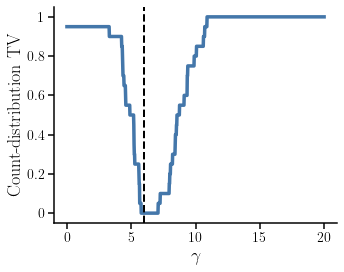

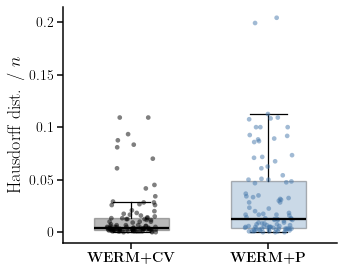

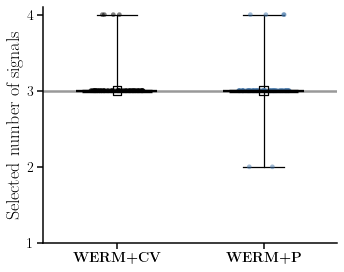

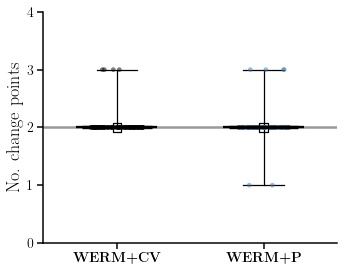

/tmp/ipykernel_401447/1537379819.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


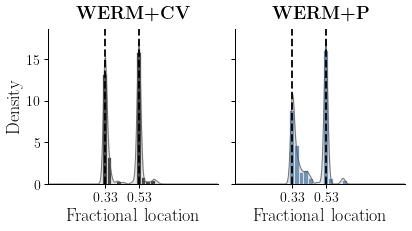

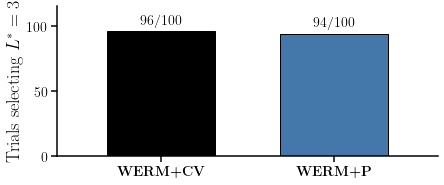

In [3]:
plot_penalty_assessment('M3', 'results/M3_genuine_logbinomial/rerun_assessment100.pkl')

## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/E_search_penalty_M3/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18, density_label_x=.07):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(density_label_x,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric == ('size' if m3 else 'runtime'):
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/E_search_penalty_M3')


### Genuine M3 logistic comparison — independent assessment only

M3_gamma_calibration


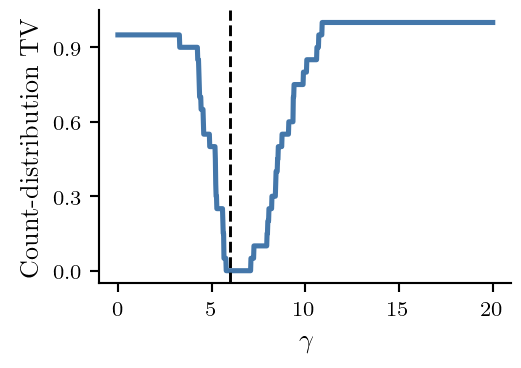

M3_location_box


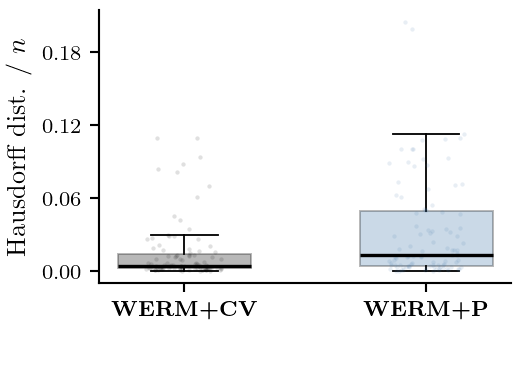

M3_counts_box


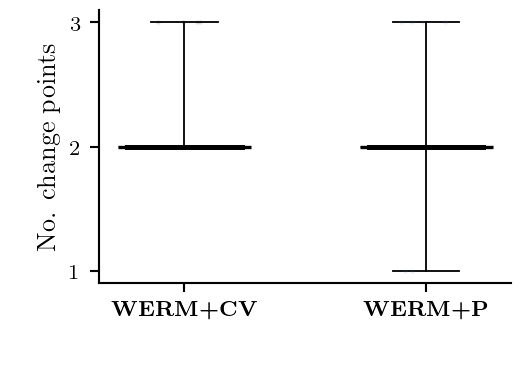

M3_signals_box


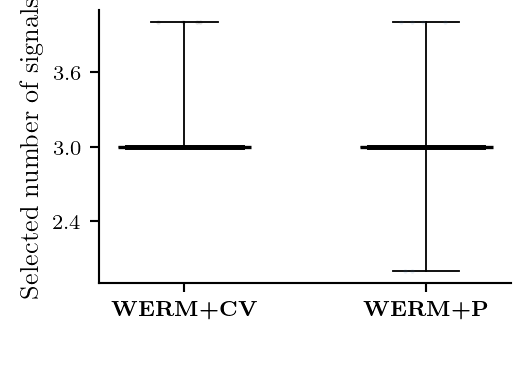

Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


/tmp/ipykernel_3337403/1827728302.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


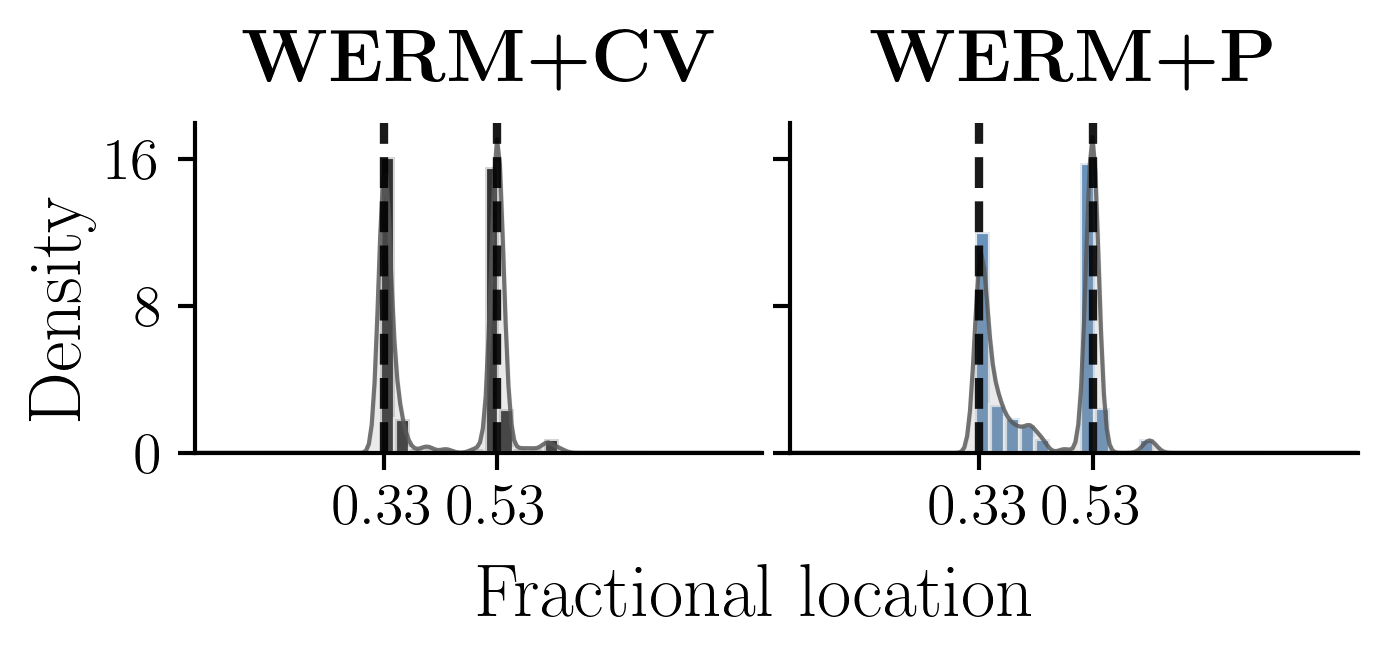

M3_correct_count_frequency


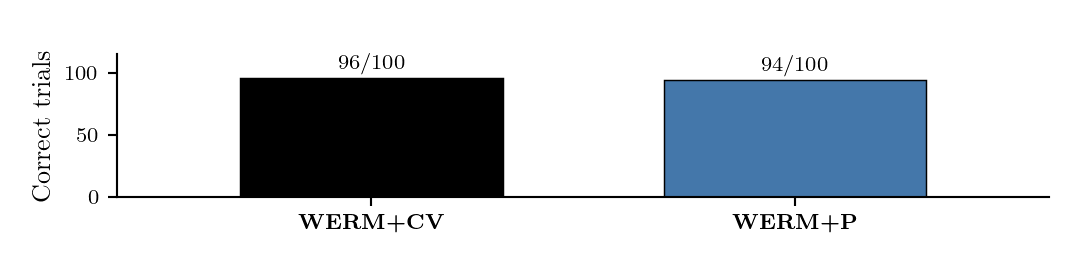

Frozen gamma: 6.0 ; correct-count trials: [96, 94]


In [2]:
from scipy.special import gammaln
saved=load_saved('results/M3_genuine_logbinomial/rerun_assessment100.pkl')
rows=saved['assessment'];design=saved['design'];n=design['n'];truth=np.asarray(design['true_cp'])
assert len(rows)==100
assert not ({r['data_hash'] for r in saved['calibration']}&{r['data_hash'] for r in rows})
Ks=np.arange(1,5);logcomb=gammaln(n)-gammaln(Ks)-gammaln(n-Ks+1)
cps=[[],[]]
for row in rows:
    k=int(np.argmin(row['raw_by_K']+saved['gamma']*logcomb)+1)
    assert k==row['penalties']['log_binomial']['K']
    cps[0].append(np.asarray(row['cv_cp']))
    cps[1].append(np.asarray(row['cp_by_K'][k]))
labels=[r'\textbf{WERM+CV}',r'\textbf{WERM+P}'];colors=['black','#4477AA']
counts=[np.array([len(cp) for cp in method]) for method in cps]
H=[]
for method in cps:
    values=[]
    for cp in method:
        dist=np.abs(cp[:,None]-truth[None,:])/n if len(cp) else None
        values.append(max(dist.min(axis=0).max(),dist.min(axis=1).max()) if len(cp) else np.nan)
    H.append(values)
with plt.rc_context(PAPER_STYLE):
    fig,ax=paper_panel();ax.plot(saved['grid'],saved['tv'],color='#4477AA',lw=3.5*SCALE)
    ax.axvline(saved['gamma'],color='black',ls='--',lw=2*SCALE)
    ax.set(xlabel=r'$\gamma$',ylabel='Count-distribution TV');export_plot(fig,'M3_gamma_calibration')
    for groups,ylabel,name in [(H,r'Hausdorff dist. / $n$','location'),
                             (counts,'No. change points','counts'),
                             ([c+1 for c in counts],'Selected number of signals','signals')]:
        simple_summary(groups,[0,1],'',ylabel,'M3_'+name+'_box',colors=colors,labels=labels)
    histogram_grid([[np.concatenate(cp)/n for cp in cps]],labels,colors,truth/n,'M3_histogram',
                   density_label_x=.015)
    fig,ax=paper_panel(full=True,height=1.5)
    fig.subplots_adjust(left=.11,right=.985,bottom=.27,top=.80)
    correct=[int(np.sum(c==len(truth))) for c in counts]
    bars=ax.bar([0,1],correct,width=.62,color=colors,edgecolor='black',lw=SCALE)
    ax.set_xticks([0,1],labels);ax.set(xlim=(-.6,1.6),ylim=(0,115),ylabel='Correct trials')
    ax.set_yticks([0,50,100])
    for bar,count in zip(bars,correct):
        ax.text(bar.get_x()+bar.get_width()/2,count+2.5,f'{count}/100',ha='center',va='bottom',fontsize=8.5)
    export_plot(fig,'M3_correct_count_frequency')
print('Frozen gamma:',saved['gamma'],'; correct-count trials:',correct)

In [3]:
verify_sources()

Exported 6 figures to results/consistent_plots_20261102/E_search_penalty_M3; saved inputs unchanged.
